# Linear Gaussian inverse problem: numerical and statistical audits

The posterior is analytic. SVD and augmented QR avoid explicitly forming a squared-condition normal-equations matrix. Their accuracy is compared to an 80-digit oracle for the actual rounded inputs. Calibration is tested separately under the joint prior-predictive distribution. This is established methodology, not a new inference algorithm.

In [1]:
import json
from pathlib import Path
report=json.loads(Path('benchmarks/results.json').read_text())
print('Predeclared gate:', report['success'])
print('SVD versus QR:', report['max_svd_qr_difference'])
for row in report['selected']:
    print(row['d'],row['method'],'median relative mean error',row['median_mean_relative_error'],'failures',row['failed'])

Predeclared gate: True
SVD versus QR: 5.405661746354819e-10
4 svd median relative mean error 3.002540359698137e-10 failures 0
4 augmented_qr median relative mean error 1.1185881368944058e-09 failures 0
4 normal_equations median relative mean error 0.09291957819256574 failures 0
12 svd median relative mean error 9.352638856144605e-10 failures 0
12 augmented_qr median relative mean error 6.012076283461579e-10 failures 0
12 normal_equations median relative mean error 0.1533080727767636 failures 0
32 svd median relative mean error 1.034907628594011e-09 failures 0
32 augmented_qr median relative mean error 5.696124974832968e-10 failures 0
32 normal_equations median relative mean error 0.15259381161134838 failures 0


In [2]:
for row in report['calibration']:
    print(row['scenario'], row['direction'], 'coverage=',row['coverage_95'], 'Wilson 95% interval=',(row['coverage_wilson_low'],row['coverage_wilson_high']))

correct strong coverage= 0.947 Wilson 95% interval= (0.9313253831625082, 0.9592534947514054)
correct weak coverage= 0.953 Wilson 95% interval= (0.9380600619184716, 0.9644728948936154)
noise_understated strong coverage= 0.145 Wilson 95% interval= (0.12453493622851891, 0.16818206229622523)
noise_understated weak coverage= 0.843 Wilson 95% interval= (0.8191441706597944, 0.8642306730191147)
prior_too_tight strong coverage= 0.945 Wilson 95% interval= (0.9290916123226243, 0.9575025726252315)
prior_too_tight weak coverage= 0.145 Wilson 95% interval= (0.12453493622851891, 0.16818206229622523)


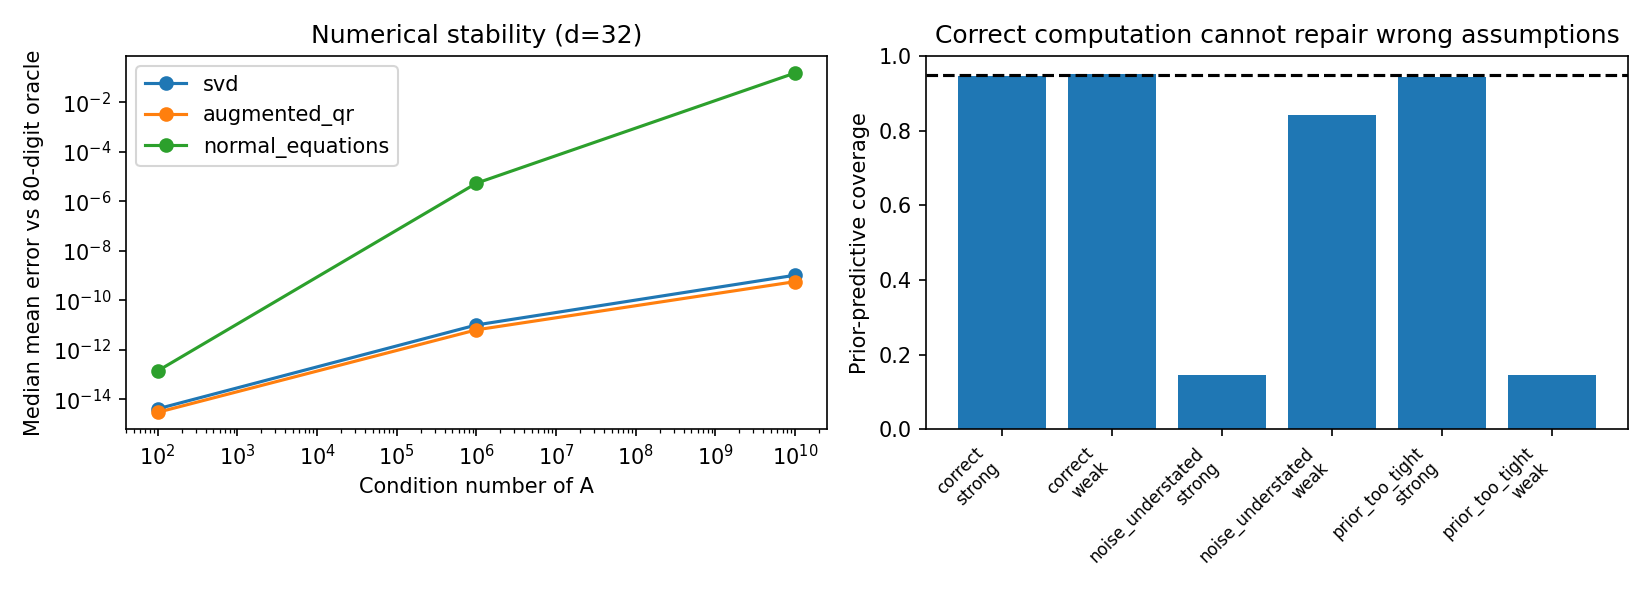

In [3]:
from IPython.display import Image,display
display(Image(filename='benchmarks/audit.png'))

In [4]:
import numpy as np
from src.posterior import posterior
a=np.diag([1.,.01,0.])
p=posterior(a,np.array([1.,.1,10.]),sigma=.1,tau=2.)
print('Mean:',p.mean)
print('Posterior variances:',np.diag(p.covariance))
assert abs(p.covariance[-1,-1]-4)<1e-12
print('The unobserved direction retains the prior variance.')

Mean: [0.99750623 0.38461538 0.        ]
Posterior variances: [0.00997506 3.84615385 4.        ]
The unobserved direction retains the prior variance.


## Conclusions and limits

Normal equations can lose accuracy despite small residuals. SVD is compared to a strong QR baseline: no universal superiority is asserted. A stable posterior still has poor coverage under an understated noise level or overly concentrated prior. Coverage here averages over draws of theta from the prior; it is not a fixed-theta frequentist guarantee. Dense finite-dimensional isotropic Gaussian assumptions exclude nonlinear operators, empirical financial calibration and model discrepancy inference.